# 26. Как восстановить движение по двум парам кадров

[Программа курса](../../README_ru.md)

Синий конец ленты почти приклеен к месту, оранжевый поднимается и возвращается обратно. Две неподвижные камеры видели ленту в четверть и в три четверти секунды. Между этими моментами кадров для обучения нет. Посмотрим, где окажется оранжевое пятно на 0.375 с, если смотреть на него ещё и сбоку.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "deformation.py").is_file())
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import deformation as motion
import deformation_demos as demos
np.set_printoptions(precision=5, suppress=True)

## Что известно до подгонки

Лента собрана из тех же пяти пятен, что и раньше. Их начальная форма, цвета, положение в покое и камеры известны. В синтетической съёмке каждому центру соответствует своя цветная метка. На вход подгонке попадают координаты этих меток в пикселях и их номера. Центры в пространстве и изображения третьей камеры остаются у генератора для проверки. Поиск соответствующих меток в произвольном видео был бы отдельной задачей.

Положение камеры и время двигаются отдельно. Для сравнения есть неподвижная лента и модель, восстановленная по меткам. Переключение между ними меняет правую картинку. Левый кадр по-прежнему берётся из синтетической съёмки. За один опыт удобно менять только ракурс или только время, а затем совместить обе проверки.

In [2]:
display(demos.lab(26, "ru"))

## Из двух пикселей в одну точку

У камер одинаковый фокус $f=64$ px, главная точка $(32,24)$ px. Левая камера стоит в начале координат, правая сдвинута на $B=0.8$ м вправо. Обе смотрят прямо. Для правого конца ленты в момент 0.25 с горизонтальная координата слева равна 44.89417 px, справа 33.30390 px. По вертикали обе дают 17.04584 px.

Разность горизонтальных меток $d=44.89417-33.30390=11.59027$ px. У снимков одна и та же глубина $Z$, поэтому $d=fB/Z$. Перенесём $Z$ налево и разделим на $d$. Получится $Z=64\cdot0.8/11.59027\approx4.4175$ м. Пиксели сократились, метры остались. Из левой координаты вычтем центр кадра и вернём масштаб глубины: $X=(44.89417-32)\cdot4.4175/64\approx0.89$ м. По вертикали $Y=(17.04584-24)\cdot4.4175/64\approx-0.48$ м. Центр поднялся, поэтому знак минус ожидаем. Через полсекунды второй стереокадр даёт $(0.89,-0.72,4.2575)$ м. Чем меньше разность $d$, тем опаснее даже ошибка в один пиксель.

In [3]:
observations = motion.stereo_tracks()
for row in observations:
    (ul, v), (ur, _) = row["left"][-1], row["right"][-1]
    z = motion.FOCAL * motion.BASELINE / (ul - ur)
    xyz = [(ul - 32)*z/64, (v - 24)*z/64, z]
    print(row["t"], "s  XYZ =", np.round(xyz, 5))

0.25 s  XYZ = [ 0.89   -0.48    4.4175]
0.75 s  XYZ = [ 0.89   -0.72    4.2575]


## Один подъём вместо позы на каждый кадр

У ленты есть секунда, чтобы выйти из исходного положения и вернуться. Нормированное время $r=t/T$ — это время в секундах, делённое на длительность $T=1$ с. В начале $r=0$, в конце $r=1$. Произведение $r(1-r)$ на обоих концах равно нулю, а в середине даёт $0.5\cdot0.5=0.25$. Умножение на четыре делает вершину равной единице. Получилась гладкая дуга $h=4r(1-r)$ без единиц измерения.

Канонический центр $p_0$ измеряется в метрах. Добавим к нему тройку смещений $a=(a_x,a_y,a_z)$, умноженную на долю подъёма $h$. В середине тройка даёт полное смещение. В четверть секунды берётся только $4\cdot0.25\cdot0.75=0.75$ от него. У каждого пятна своя тройка.

$$
p(t)=p_0+h(t)\,a.
$$

У оранжевого конца исходная высота ноль. Для двух наблюдений вертикальные смещения равны −0.48 и −0.72 м. Обе доли подъёма равны 0.75. Если искать амплитуду по отдельности, выйдут $-0.48/0.75=-0.64$ м и $-0.72/0.75=-0.96$ м. Одна дуга не может пройти через обе точки, потому что сама съёмка слегка покачивается вбок и вверх. При равных долях подъёма середина двух ответов минимизирует сумму квадратов ошибок: $(-0.64-0.96)/2=-0.8$ м.

Если времена разные, доли могут различаться. Для одного направления обозначим измеренное смещение через $d_k$, а амплитуду через $a$. Буква $k$ нумерует моменты. Остаток между прогнозом и наблюдением равен $h_k a-d_k$ метра. Возведём каждый остаток в квадрат и сложим. Производная квадрата даёт удвоенный остаток, а его изменение по $a$ вносит ещё один множитель $h_k$. В самой нижней точке этой параболы наклон равен нулю. Отсюда:

$$
\begin{aligned}
0 &= \sum_k 2h_k(h_k a-d_k),\\
a\sum_k h_k^2 &= \sum_k h_k d_k,\\
a &= \frac{\sum_k h_k d_k}{\sum_k h_k^2}.
\end{aligned}
$$

Числитель для вертикали равен $0.75(-0.48)+0.75(-0.72)=-0.9$ м. Знаменатель $0.75^2+0.75^2=1.125$ без единиц. Деление снова даёт −0.8 м. Если есть только начало и конец записи, то обе доли нулевые и знаменатель равен нулю. По двум кадрам ленты в покое нельзя узнать высоту подъёма.

In [4]:
model = motion.fit_motion(motion.ribbon(), observations)
print("a =", np.round(model["amplitudes"][-1], 5))
print("t = 0.375 s:", np.round(motion.scene_at(model, .375)["splats"][-1]["center"], 5))

a = [ 0.12 -0.8   0.45]
t = 0.375 s: [ 0.9125  -0.75     4.42188]


## Три проверки по отдельности

Начнём с левой камеры и момента 0.375 с. Камера знакома, такого времени в наблюдениях не было. Затем вернём обучающее время 0.25 с, но повернём камеру на 32°. Это другой тест. Для третьего возьмём сразу и 0.375 с, и 32°. В каждой строке ниже ошибка MSE усредняет квадраты разностей по всем $65\cdot49\cdot3=9555$ цветовым значениям. Для сравнения используется исходная яркость каналов от 0 до 1.

У последнего пятна в момент 0.375 с доля $h=4\cdot0.375\cdot0.625=0.9375$. Высота модели $0-0.8\cdot0.9375=-0.75$ м. У исходного движения $-0.66515$ м: модель подняла конец примерно на 8.5 см выше. В незнакомом ракурсе при этом же времени ошибка кадра уменьшается примерно с 0.007119 у неподвижной ленты до 0.000364 у подогнанной. На карте разностей яркий край показывает, где промах заметнее фона.

t        angle   MSE(static)   MSE(fitted)
0.375      0     0.00937542    0.00061671
0.250     32     0.00527760    0.00072072
0.375     32     0.00711925    0.00036425


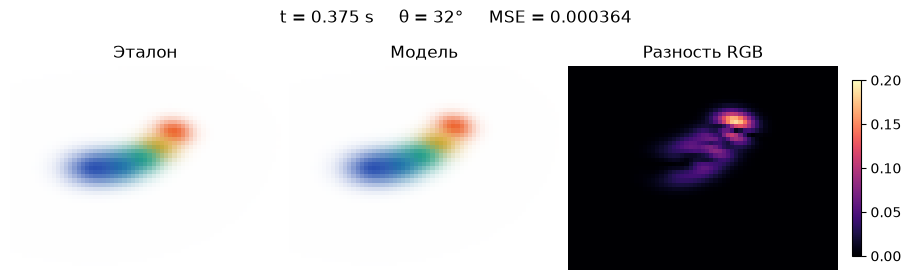

In [5]:
print("t        angle   MSE(static)   MSE(fitted)")
for time, angle in [(.375, 0), (.25, 32), (.375, 32)]:
    target = demos.frame(motion.reference_scene(time), angle)
    static = demos.frame(model["canonical"], angle)
    fitted = demos.frame(motion.scene_at(model, time), angle)
    print(f"{time:.3f}    {angle:3}     {np.mean((static-target)**2):.8f}    {np.mean((fitted-target)**2):.8f}")
fig = demos.fit_figure(lang="ru")
plt.show()

## Движение между снимками

У модели высота последнего пятна в моменты 0.25, 0.5 и 0.75 с равна −0.6, −0.8 и −0.6 м. Средняя скорость на первом промежутке $(-0.8+0.6)/0.25=-0.8$ м/с, на втором $(-0.6+0.8)/0.25=+0.8$ м/с. Она меняет знак, когда кончик разворачивается. Форма траектории задаётся одной гладкой дугой для всей секунды, поэтому у границы между кадрами скачка нет. На графике видно и ограничение этой гладкости. Две чёрные метки стоят на разных высотах, а симметричная дуга на четверти и трёх четвертях записи всегда даёт одинаковую высоту. Ошибка движения может сохраниться даже при маленькой средней ошибке изображения.

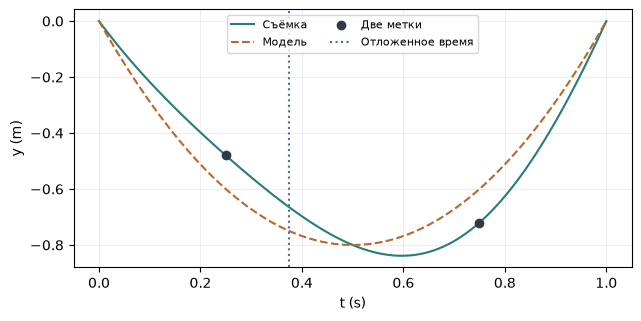

In [6]:
fig = demos.motion_plot(lang="ru")
plt.show()

## Что остаётся в файле

Для повторного просмотра достаточно исходной ленты, длительности в секундах и пяти троек амплитуд. Снимки и метки больше не нужны. После записи и чтения из файла для того же момента и ракурса должен получиться тот же кадр. В веб-опыте этот же формат принимает поле «Движение из JSON». При открытии собственного файла первая картинка показывает его исходную сцену. Без эталонной съёмки MSE неизвестна.

In [7]:
folder = root / "dynamic-scene-result"
folder.mkdir(exist_ok=True)
path = folder / "lesson-26-ru.json"
path.write_text(json.dumps(model, allow_nan=False), encoding="utf8")
restored = motion.validate_model(json.loads(path.read_text(encoding="utf8")))
np.testing.assert_array_equal(demos.frame(motion.scene_at(restored, .375), 32),
                              demos.frame(motion.scene_at(model, .375), 32))
print(path.name, "·", len(restored["amplitudes"]), "× XYZ")

lesson-26-ru.json · 5 × XYZ


## Что случится с шумной меткой

В исходном наблюдении на 0.25 с правая метка сдвинулась на +1 px, левая осталась на месте. Куда переместится вычисленная точка? Будет ли подогнанная дуга обязана пройти ровно через неё?

<details>
<summary>Разбор</summary>

Разность координат упадёт с 11.59027 до 10.59027 px. При том же числителе 51.2 получаем глубину $51.2/10.59027\approx4.835$ м. Вместо прежних 4.4175 м точка окажется примерно на 42 см дальше. Вертикальная координата левой метки не менялась, но перевод в метры использует новую глубину. У дуги по-прежнему одна амплитуда на направление и два наблюдения. Она выбирает компромисс. Ползунок ошибки вносит попеременно положительную и отрицательную поправку в правые метки, чтобы этот эффект был воспроизводим.

</details>